# Introducción a Tensorflow 2


In [202]:
import tensorflow as tf
print(tf.__version__)

2.20.0


In [203]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.metrics import confusion_matrix

## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos
![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

In [204]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

El conjunto de entrenamiento está formado por 60.000 imágenes de 28x28, mientras que el de test lo forman 10.000 imágenes. El problema de clasificación consiste en distinguir entre los 10 dígitos diferentes

In [205]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [5 0 4 1 9]


## Pre-procesamiento
Como suele ser habitual, es conveniente realizar algún tipo de procesamiento antes de que los datos sean tratados por el modelo. En este caso, haremos un pequeño procesamiento que consiste en escalar los valores entre 0 y 1. Para ello, bastará con dividir por 255, ya que cada pixel de las imágenes de entrada viene representado por un entero entre 0 y 255 (8 bits) indicando su tonalidad de gris.

In [206]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype

dtype('float64')

## Modelo
Para crear un modelo, primero tenemos que definir la arquitectura neuronal. El caso más sencillo es definir una estructura secuencial de capas, donde la primera actúa de capa de entrada y la última de salida del modelo. Cada capa tendrá una serie de parámetros dependiendo del tipo, habitualmente habrá que especificar el tamaño (número de neuronas), función de activación, etc.

In [207]:
tf.random.set_seed(42)
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

## Entrenamiento
Antes de entrenar, hay que compilar el modelo indicando:
- La **regla de aprendizaje** (*optimizer*) que define el algoritmo para actualizar los pesos sinápticos de la red
- La **función objetivo** o de pérdida (*loss*), que es optimizada por la regla de aprendizaje
- La **métrica** o medida de evaluación (*metrics*) utilizada para evaluar el modelo entrenado

In [208]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

inicio = time.time()

Tras compilar el modelo, el entrenamiento se define mediante los siguientes parámetros:
- **Épocas** (*epochs*). Número de veces que se le muestra el conjunto de entrenamiento al modelo
- Tamaño de **lote** (*batch_size*). Número de instancias o patrones que se muestran al modelo para actualizar los pesos sinápticos
- Conjunto de **validación** (*validation_spli*). Datos utilizados para medir el rendimiento durante el entrenamiento

En este caso, se ha optado por los valores por defecto

In [209]:
h=model.fit(x_train, y_train, epochs=5)
fin = time.time()
tiempo_original = fin - inicio
print("Tiempo de entrenamiento:", tiempo_original, "segundos")

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9265 - loss: 0.2545
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9671 - loss: 0.1124
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9776 - loss: 0.0770
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9839 - loss: 0.0562
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9879 - loss: 0.0424
Tiempo de entrenamiento: 37.72542428970337 segundos


## Evaluación
Una vez entrenada la red neuronal, prodremos obtener las medidas de rendimiento espcificadas en la etapa anterior, tanto para el conjunto de entrenamiento como para el conjunto de test

In [210]:
loss_train, acc_train = model.evaluate(x_train, y_train)
loss_test, acc_test = model.evaluate(x_test, y_test)
print("Accuracy entrenamiento:", acc_train)
print("Accuracy test:", acc_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9901 - loss: 0.0339
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9757 - loss: 0.0797
Accuracy entrenamiento: 0.9901333451271057
Accuracy test: 0.9757000207901001


In [211]:
# Errores del modelo original

y_pred_train = np.argmax(model.predict(x_train), axis=1)
y_pred_test = np.argmax(model.predict(x_test), axis=1)

errores_train_original = int(np.sum(y_pred_train != y_train))
errores_test_original = int(np.sum(y_pred_test != y_test))

print("Errores entrenamiento:", errores_train_original)
print("Errores test:", errores_test_original)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Errores entrenamiento: 592
Errores test: 243


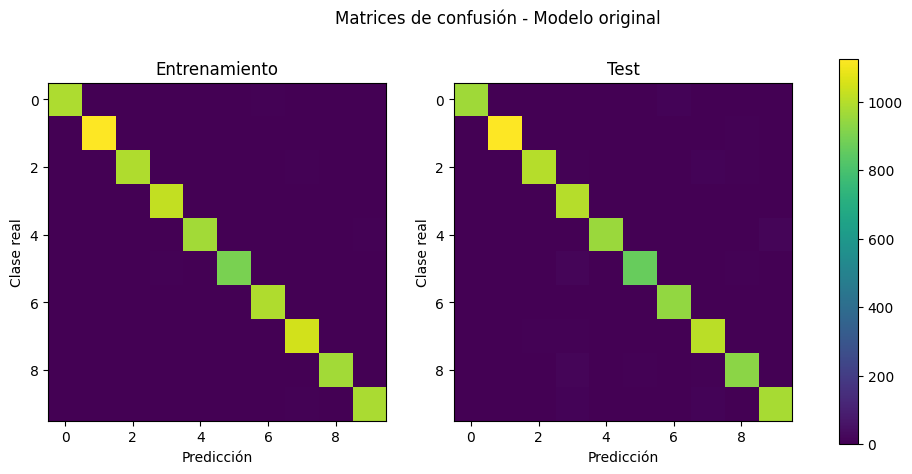

In [212]:
# Matrices de confusión del modelo original

cm_train_original = confusion_matrix(y_train, y_pred_train)
cm_test_original = confusion_matrix(y_test, y_pred_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de entrenamiento
axes[0].imshow(cm_train_original)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

# Matriz de test
axes[1].imshow(cm_test_original)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - Modelo original")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

## **Experimentos**

### Experimento 1

In [213]:
tf.random.set_seed(42)
model1 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(256, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [214]:
model1.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [215]:
inicio = time.time()

h1 = model1.fit(x_train, y_train, epochs=5)

fin = time.time()
tiempo_256 = fin - inicio

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9342 - loss: 0.2258
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9726 - loss: 0.0928
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9821 - loss: 0.0596
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9880 - loss: 0.0404
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9920 - loss: 0.0278


In [216]:
loss_train_256, acc_train_256 = model1.evaluate(x_train, y_train)
loss_test_256, acc_test_256 = model1.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9931 - loss: 0.0236
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9773 - loss: 0.0770


In [217]:
y_pred_train_256 = np.argmax(model1.predict(x_train), axis=1)
y_pred_test_256 = np.argmax(model1.predict(x_test), axis=1)

errores_train_256 = int(np.sum(y_pred_train_256 != y_train))
errores_test_256 = int(np.sum(y_pred_test_256 != y_test))

cm_train_256 = confusion_matrix(y_train, y_pred_train_256)
cm_test_256 = confusion_matrix(y_test, y_pred_test_256)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


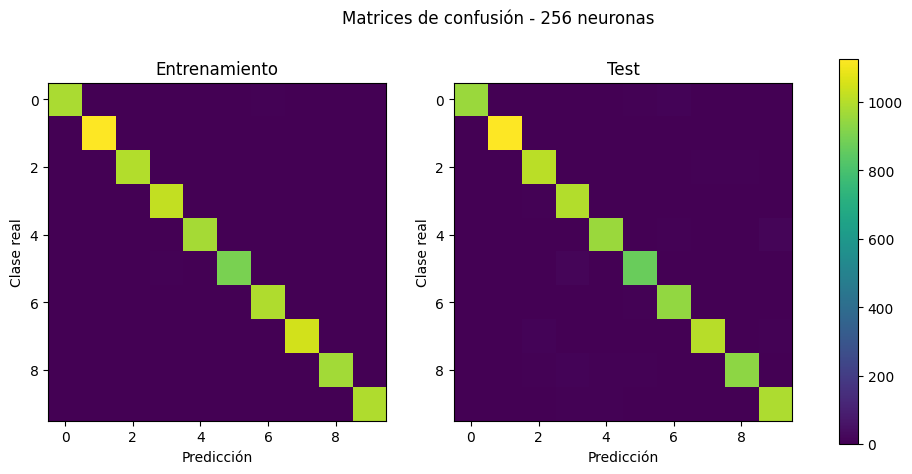

In [218]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_256)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_256)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - 256 neuronas")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he aumentado el número de neuronas de la capa oculta de 128 a 256, manteniendo el resto de parámetros igual que en el modelo original.

El resultado mejora ligeramente respecto al modelo original, tanto en entrenamiento como en test. Esto tiene sentido porque al tener más neuronas, la red tiene más capacidad para aprender y representar los patrones de las imágenes.

El tiempo de entrenamiento también aumenta ligeramente, ya que al haber más neuronas hay más pesos que calcular y actualizar.

### Experimento 2

In [219]:
tf.random.set_seed(42)
model2 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(64, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [220]:
model2.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [221]:
inicio = time.time()

h2 = model2.fit(x_train, y_train, epochs=5)

fin = time.time()
tiempo_64 = fin - inicio

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9146 - loss: 0.2997
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9584 - loss: 0.1451
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9699 - loss: 0.1057
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9761 - loss: 0.0838
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9802 - loss: 0.0689


In [222]:
loss_train_64, acc_train_64 = model2.evaluate(x_train, y_train)
loss_test_64, acc_test_64 = model2.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9826 - loss: 0.0585
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9737 - loss: 0.0923


In [223]:
y_pred_train_64 = np.argmax(model2.predict(x_train), axis=1)
y_pred_test_64 = np.argmax(model2.predict(x_test), axis=1)

errores_train_64 = int(np.sum(y_pred_train_64 != y_train))
errores_test_64 = int(np.sum(y_pred_test_64 != y_test))

cm_train_64 = confusion_matrix(y_train, y_pred_train_64)
cm_test_64 = confusion_matrix(y_test, y_pred_test_64)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


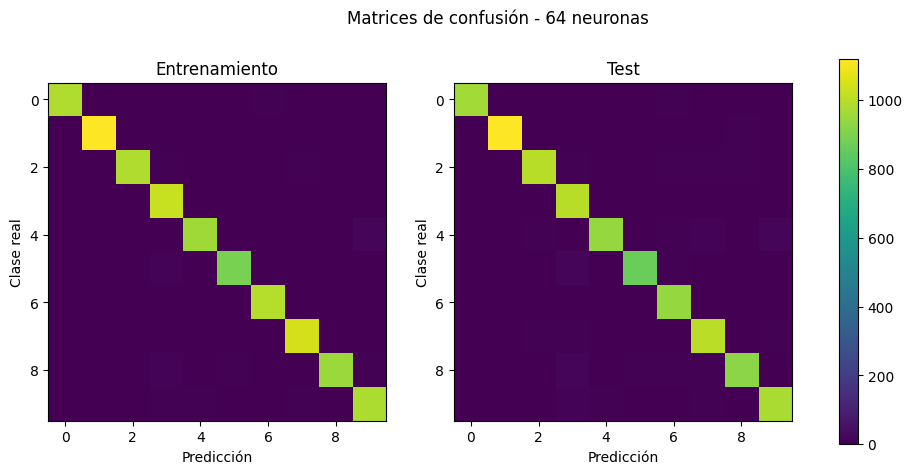

In [224]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_64)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_64)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - 64 neuronas")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he reducido el número de neuronas de 128 a 64, manteniendo el resto de parámetros igual.

El rendimiento disminuye respecto al modelo original. Esto puede deberse a que al tener menos neuronas la red tiene una menor capacidad para representar los patrones de las imágenes.

El tiempo de entrenamiento también es algo menor, ya que la red tiene menos neuronas y, por tanto, menos cálculos que realizar.

El resultado es coherente con el experimento anterior, ya que aumentar el número de neuronas mejora ligeramente el resultado, mientras que reducirlas lo empeora.

### Experimento 3

In [225]:
tf.random.set_seed(42)
model3 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [226]:
model3.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [227]:
inicio = time.time()

h3 = model3.fit(x_train, y_train, epochs=10)

fin = time.time()
tiempo_10 = fin - inicio

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9266 - loss: 0.2572
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9667 - loss: 0.1131
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9774 - loss: 0.0769
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9836 - loss: 0.0559
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9886 - loss: 0.0412
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9917 - loss: 0.0305
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9936 - loss: 0.0234
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9957 - loss: 0.0179
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9961 - loss: 0.0154
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9962 - loss: 0.0130


In [228]:
loss_train_10, acc_train_10 = model3.evaluate(x_train, y_train)
loss_test_10, acc_test_10 = model3.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9935 - loss: 0.0193
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9759 - loss: 0.0979


In [229]:
y_pred_train_10 = np.argmax(model3.predict(x_train), axis=1)
y_pred_test_10 = np.argmax(model3.predict(x_test), axis=1)

errores_train_10 = int(np.sum(y_pred_train_10 != y_train))
errores_test_10 = int(np.sum(y_pred_test_10 != y_test))

cm_train_10 = confusion_matrix(y_train, y_pred_train_10)
cm_test_10 = confusion_matrix(y_test, y_pred_test_10)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


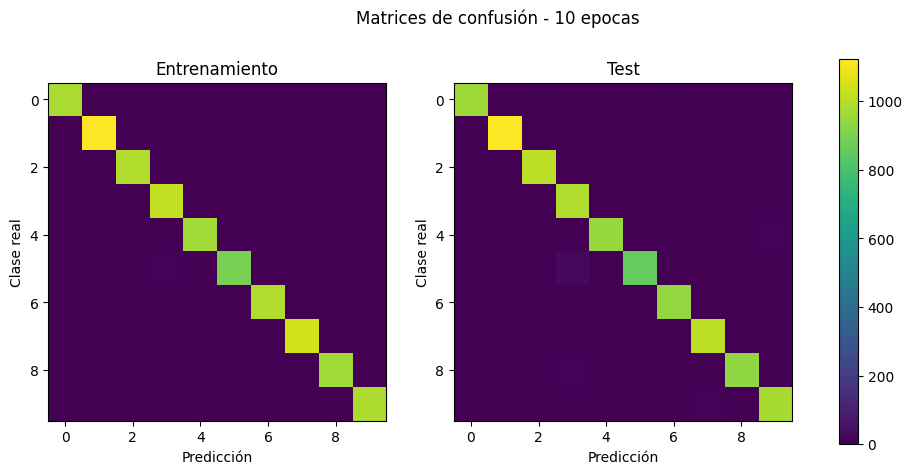

In [230]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_10)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_10)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - 10 epocas")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he aumentado el número de épocas de 5 a 10.

El rendimiento en entrenamiento mejora bastante, mientras que el resultado en test se mantiene prácticamente igual al del modelo original. Esto ocurre porque al realizar más épocas el modelo tiene más oportunidades de aprender de los datos de entrenamiento.

Sin embargo, después de varias épocas las mejoras sobre datos que el modelo no ha visto durante el entrenamiento son menores. Por eso no produce una mejora apreciable en test.

Como era de esperar, el tiempo de entrenamiento también aumenta, ya que el modelo tiene que recorrer el conjunto de entrenamiento el doble de veces.

### Experimento 4

In [231]:
tf.random.set_seed(42)
model4 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [232]:
model4.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [233]:

inicio = time.time()

h4 = model4.fit(x_train, y_train, epochs=20)

fin = time.time()
tiempo_20 = fin - inicio

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9267 - loss: 0.2556
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9671 - loss: 0.1105
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9780 - loss: 0.0751
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9840 - loss: 0.0549
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9883 - loss: 0.0409
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9918 - loss: 0.0302
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9943 - loss: 0.0224
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9951 - loss: 0.0185
Epoch 9/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9962 - loss: 0.0149
Epoch 10/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9967 - loss: 0.0124
Epoch 11/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9967 - loss: 0.0119
Epoch 12/20
1875/1875 ━━━━━━━━

In [234]:
loss_train_20, acc_train_20 = model4.evaluate(x_train, y_train)
loss_test_20, acc_test_20 = model4.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9983 - loss: 0.0053
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9779 - loss: 0.1139


In [235]:
y_pred_train_20 = np.argmax(model4.predict(x_train), axis=1)
y_pred_test_20 = np.argmax(model4.predict(x_test), axis=1)

errores_train_20 = int(np.sum(y_pred_train_20 != y_train))
errores_test_20 = int(np.sum(y_pred_test_20 != y_test))

cm_train_20 = confusion_matrix(y_train, y_pred_train_20)
cm_test_20 = confusion_matrix(y_test, y_pred_test_20)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


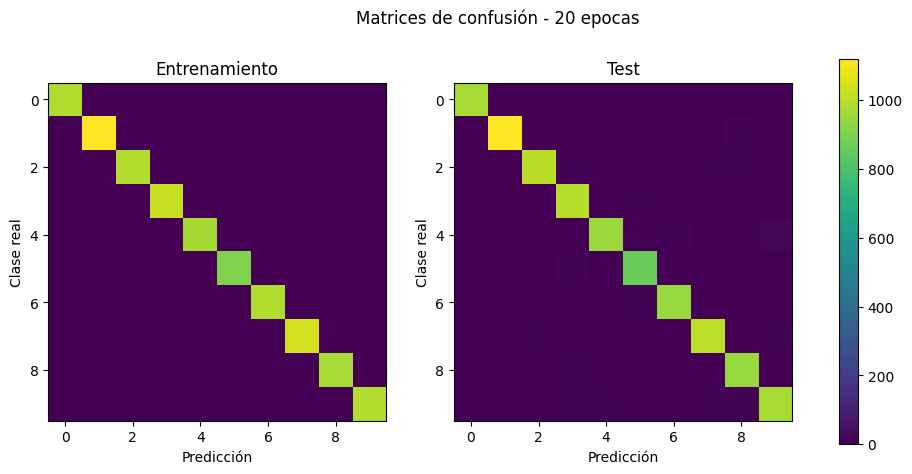

In [236]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_20)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_20)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - 20 epocas")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he aumentado el número de épocas hasta 20.

El rendimiento en entrenamiento sigue mejorando, y el resultado en test también mejora respecto al modelo original, aunque la mejora es más pequeña que en entrenamiento.

Esto muestra que seguir entrenando permite al modelo aprender mejor los datos de entrenamiento, pero llega un punto en el que las mejoras sobre el conjunto de test son más pequeñas.

Además, el tiempo de entrenamiento aumenta bastante porque el modelo realiza muchas más pasadas por el conjunto de datos. La diferencia entre entrenamiento y test también aumenta, lo que puede indicar cierto sobreajuste.

### Experimento 5

In [237]:
tf.random.set_seed(42)
model5 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [238]:
model5.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [239]:
inicio = time.time()

h5 = model5.fit(x_train, y_train, epochs=5)

fin = time.time()
tiempo_sgd = fin - inicio

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8367 - loss: 0.6462
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9045 - loss: 0.3407
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9169 - loss: 0.2951
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9250 - loss: 0.2653
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9319 - loss: 0.2417


In [240]:
loss_train_sgd, acc_train_sgd = model5.evaluate(x_train, y_train)
loss_test_sgd, acc_test_sgd = model5.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9359 - loss: 0.2293
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9356 - loss: 0.2240


In [241]:
y_pred_train_sgd = np.argmax(model5.predict(x_train), axis=1)
y_pred_test_sgd = np.argmax(model5.predict(x_test), axis=1)

errores_train_sgd = int(np.sum(y_pred_train_sgd != y_train))
errores_test_sgd = int(np.sum(y_pred_test_sgd != y_test))

cm_train_sgd = confusion_matrix(y_train, y_pred_train_sgd)
cm_test_sgd = confusion_matrix(y_test, y_pred_test_sgd)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


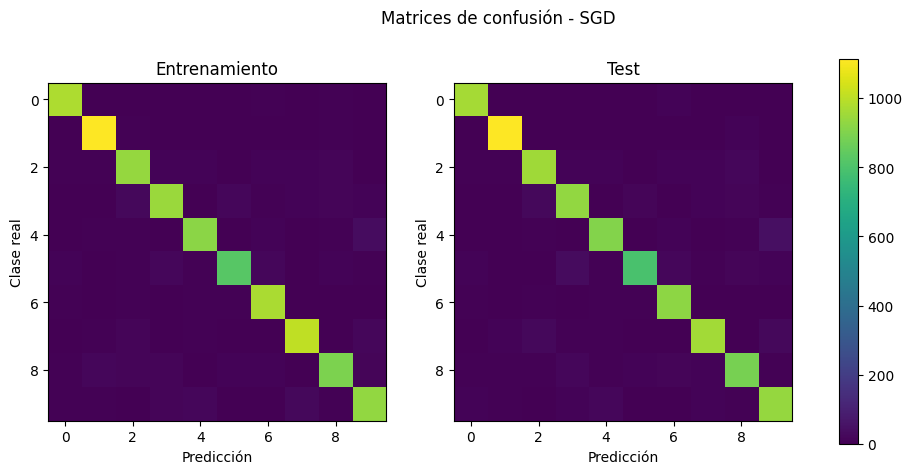

In [242]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_sgd)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_sgd)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - SGD")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he cambiado el optimizador Adam por SGD, manteniendo el resto de parámetros igual.

El rendimiento obtenido es bastante menor que con Adam. Esto puede deberse a que, con solo 5 épocas, SGD necesita más tiempo para conseguir un nivel de aprendizaje similar en este modelo.

Por tanto, en esta configuración concreta Adam consigue aprender más rápidamente. No significa que SGD sea siempre peor, sino que con los parámetros utilizados en este experimento no obtiene un resultado tan bueno.

El tiempo de entrenamiento es del mismo orden, ya que el modelo tiene la misma arquitectura y el mismo número de épocas, aunque puede variar dependiendo del optimizador.

### Experimento 6

In [243]:
tf.random.set_seed(42)
model6 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [244]:
model6.compile(optimizer='rmsprop',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [245]:
inicio = time.time()

h6 = model6.fit(x_train, y_train, epochs=5)

fin = time.time()
tiempo_rmsprop = fin - inicio

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9247 - loss: 0.2604
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9639 - loss: 0.1212
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9747 - loss: 0.0876
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9807 - loss: 0.0690
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9842 - loss: 0.0570


In [246]:
loss_train_rmsprop, acc_train_rmsprop = model6.evaluate(x_train, y_train)
loss_test_rmsprop, acc_test_rmsprop = model6.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9846 - loss: 0.0520
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9721 - loss: 0.1003


In [247]:
y_pred_train_rmsprop = np.argmax(model6.predict(x_train), axis=1)
y_pred_test_rmsprop = np.argmax(model6.predict(x_test), axis=1)

errores_train_rmsprop = int(np.sum(y_pred_train_rmsprop != y_train))
errores_test_rmsprop = int(np.sum(y_pred_test_rmsprop != y_test))

cm_train_rmsprop = confusion_matrix(y_train, y_pred_train_rmsprop)
cm_test_rmsprop = confusion_matrix(y_test, y_pred_test_rmsprop)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


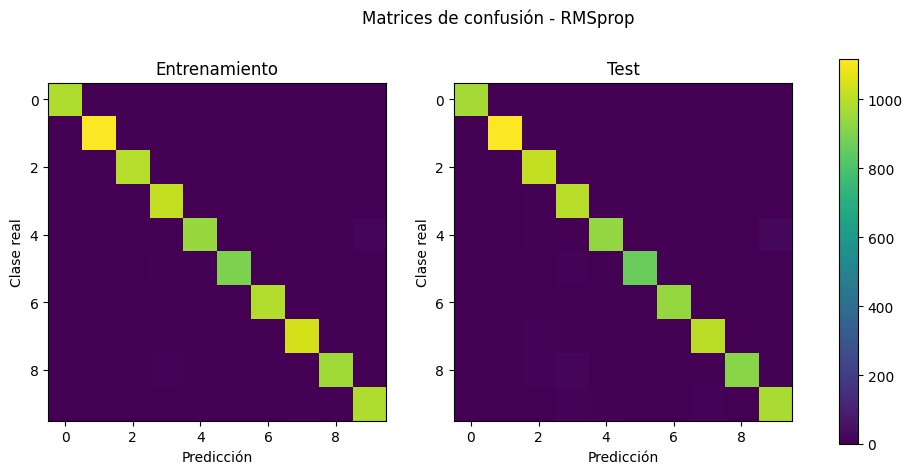

In [248]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_rmsprop)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_rmsprop)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - RMSprop")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he sustituido Adam por RMSprop, manteniendo el resto de parámetros.

El resultado es muy parecido al del modelo original con Adam, por lo que en este caso cambiar de optimizador no produce una diferencia importante en el rendimiento.

El tiempo de entrenamiento también es parecido, ya que se mantiene la misma arquitectura y el mismo número de épocas.

Los resultados tienen sentido porque ambos optimizadores consiguen entrenar correctamente la red con esta configuración.

### Experimento 7

In [249]:
tf.random.set_seed(42)
model7 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [250]:
model7.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [251]:
inicio = time.time()

h7 = model7.fit(x_train, y_train, epochs=5, batch_size=32)

fin = time.time()
tiempo_batch32 = fin - inicio

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9264 - loss: 0.2575
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9670 - loss: 0.1133
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9773 - loss: 0.0774
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9834 - loss: 0.0567
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9881 - loss: 0.0421


In [252]:
loss_train_batch32, acc_train_batch32 = model7.evaluate(x_train, y_train)
loss_test_batch32, acc_test_batch32 = model7.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9887 - loss: 0.0374
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9736 - loss: 0.0854


In [253]:
y_pred_train_batch32 = np.argmax(model7.predict(x_train), axis=1)
y_pred_test_batch32 = np.argmax(model7.predict(x_test), axis=1)

errores_train_batch32 = int(np.sum(y_pred_train_batch32 != y_train))
errores_test_batch32 = int(np.sum(y_pred_test_batch32 != y_test))

cm_train_batch32 = confusion_matrix(y_train, y_pred_train_batch32)
cm_test_batch32 = confusion_matrix(y_test, y_pred_test_batch32)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


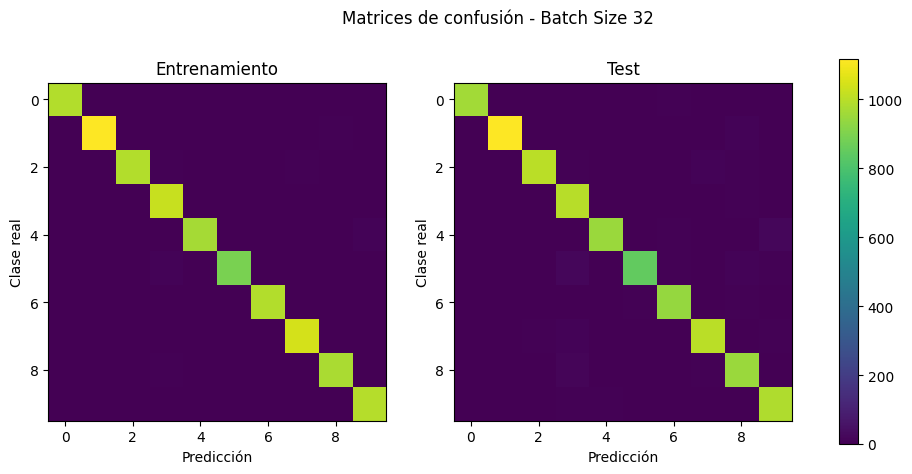

In [254]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_batch32)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_batch32)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - Batch Size 32")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he utilizado un batch size de 32 en lugar del valor utilizado por defecto.

El resultado es muy parecido al del modelo original, por lo que utilizar un lote más pequeño no produce una mejora importante en este caso.

Un batch size más pequeño hace que los pesos se actualicen más veces durante cada época. Esto puede hacer que el entrenamiento sea algo diferente, pero en este caso no se observa una mejora significativa en el resultado final.

El tiempo de entrenamiento puede ser diferente porque se realizan más actualizaciones de los pesos durante cada época.

### Experimento 8

In [255]:
tf.random.set_seed(42)
model8 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [256]:
model8.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [257]:
inicio = time.time()

h8 = model8.fit(x_train, y_train, epochs=5, batch_size=64)

fin = time.time()
tiempo_batch64 = fin - inicio

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9163 - loss: 0.2940
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9619 - loss: 0.1324
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9734 - loss: 0.0914
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9805 - loss: 0.0684
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9850 - loss: 0.0533


In [258]:
loss_train_batch64, acc_train_batch64 = model8.evaluate(x_train, y_train)
loss_test_batch64, acc_test_batch64 = model8.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9882 - loss: 0.0423
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9753 - loss: 0.0796


In [259]:
y_pred_train_batch64 = np.argmax(model8.predict(x_train), axis=1)
y_pred_test_batch64 = np.argmax(model8.predict(x_test), axis=1)

errores_train_batch64 = int(np.sum(y_pred_train_batch64 != y_train))
errores_test_batch64 = int(np.sum(y_pred_test_batch64 != y_test))

cm_train_batch64 = confusion_matrix(y_train, y_pred_train_batch64)
cm_test_batch64 = confusion_matrix(y_test, y_pred_test_batch64)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


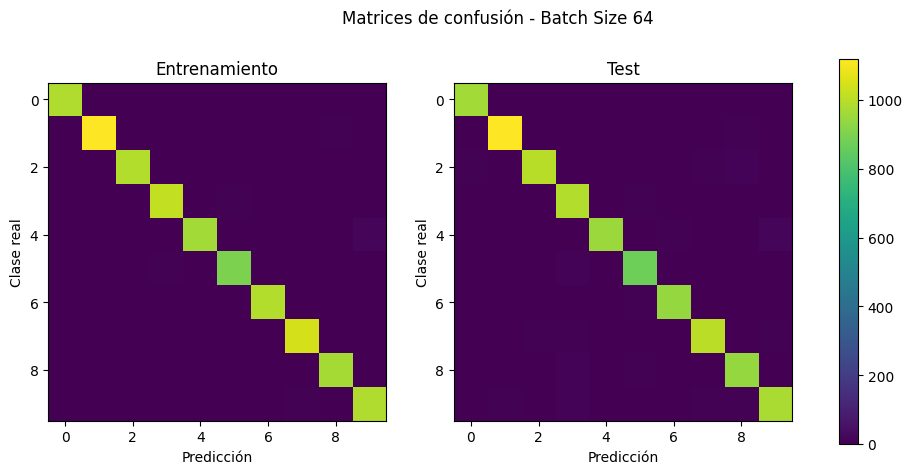

In [260]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_batch64)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_batch64)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - Batch Size 64")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he utilizado un batch size de 64.

El resultado vuelve a ser muy parecido al modelo original y al obtenido con batch size 32. Por tanto, en este caso cambiar el tamaño del lote entre estos valores no produce una diferencia importante en el rendimiento.

Al utilizar lotes más grandes se realizan menos actualizaciones de los pesos durante cada época, por lo que también puede cambiar el tiempo necesario para realizar el entrenamiento.

### Experimento 9

In [261]:
tf.random.set_seed(42)
model9 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [262]:
model9.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [263]:
inicio = time.time()

h9 = model9.fit(x_train, y_train, epochs=5, batch_size=128)

fin = time.time()
tiempo_batch128 = fin - inicio

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9001 - loss: 0.3621
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9536 - loss: 0.1629
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9666 - loss: 0.1161
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9741 - loss: 0.0900
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9796 - loss: 0.0725


In [264]:
loss_train_batch128, acc_train_batch128 = model9.evaluate(x_train, y_train)
loss_test_batch128, acc_test_batch128 = model9.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9825 - loss: 0.0617
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9715 - loss: 0.0900


In [265]:
y_pred_train_batch128 = np.argmax(model9.predict(x_train), axis=1)
y_pred_test_batch128 = np.argmax(model9.predict(x_test), axis=1)

errores_train_batch128 = int(np.sum(y_pred_train_batch128 != y_train))
errores_test_batch128 = int(np.sum(y_pred_test_batch128 != y_test))

cm_train_batch128 = confusion_matrix(y_train, y_pred_train_batch128)
cm_test_batch128 = confusion_matrix(y_test, y_pred_test_batch128)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


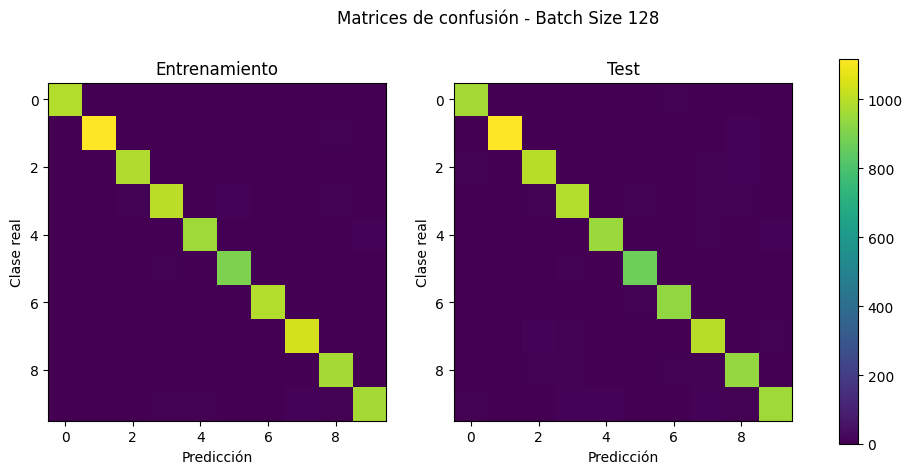

In [266]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cm_train_batch128)
axes[0].set_title("Entrenamiento")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].imshow(cm_test_batch128)
axes[1].set_title("Test")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase real")

plt.suptitle("Matrices de confusión - Batch Size 128")
plt.colorbar(axes[1].images[0], ax=axes)
plt.show()

En este experimento he aumentado el batch size hasta 128.

El resultado en test es algo peor que con los tamaños de lote anteriores. Esto puede deberse a que, al utilizar lotes más grandes, se realizan menos actualizaciones de los pesos durante cada época.

Con solamente 5 épocas, este número de actualizaciones puede no ser suficiente para conseguir el mismo rendimiento que con lotes más pequeños.

Por tanto, en estos experimentos los tamaños de lote 32 y 64 producen resultados similares, mientras que 128 obtiene un resultado algo peor.

## **Resultados**

En las matrices de confusión se puede ver que la mayoría de los resultados están en la diagonal, lo que significa que el modelo clasifica correctamente la mayoría de las imágenes. Los resultados que están fuera de la diagonal son los errores, es decir, cuando el modelo confunde un dígito con otro.

Las matrices de entrenamiento y test son bastante parecidas. En test hay algunos errores más porque esas imágenes no se han utilizado para entrenar el modelo.


In [267]:
resultados = [
    ["Original", acc_train, errores_train_original, acc_test, errores_test_original, tiempo_original],
    ["256 neuronas", acc_train_256, errores_train_256, acc_test_256, errores_test_256, tiempo_256],
    ["64 neuronas", acc_train_64, errores_train_64, acc_test_64, errores_test_64, tiempo_64],
    ["10 épocas", acc_train_10, errores_train_10, acc_test_10, errores_test_10, tiempo_10],
    ["20 épocas", acc_train_20, errores_train_20, acc_test_20, errores_test_20, tiempo_20],
    ["SGD", acc_train_sgd, errores_train_sgd, acc_test_sgd, errores_test_sgd, tiempo_sgd],
    ["RMSprop", acc_train_rmsprop, errores_train_rmsprop, acc_test_rmsprop, errores_test_rmsprop, tiempo_rmsprop],
    ["Batch 32", acc_train_batch32, errores_train_batch32, acc_test_batch32, errores_test_batch32, tiempo_batch32],
    ["Batch 64", acc_train_batch64, errores_train_batch64, acc_test_batch64, errores_test_batch64, tiempo_batch64],
    ["Batch 128", acc_train_batch128, errores_train_batch128, acc_test_batch128, errores_test_batch128, tiempo_batch128]
]

print("Configuración | Accuracy train | Errores train | Accuracy test | Errores test | Tiempo")

for resultado in resultados:
    print(resultado[0], "|",
          round(resultado[1] * 100, 2), "% |",
          resultado[2], "|",
          round(resultado[3] * 100, 2), "% |",
          resultado[4], "|",
          round(resultado[5], 2), "s")

Configuración | Accuracy train | Errores train | Accuracy test | Errores test | Tiempo
Original | 99.01 % | 592 | 97.57 % | 243 | 37.73 s
256 neuronas | 99.31 % | 413 | 97.73 % | 227 | 49.04 s
64 neuronas | 98.26 % | 1046 | 97.37 % | 263 | 27.59 s
10 épocas | 99.35 % | 392 | 97.59 % | 241 | 76.37 s
20 épocas | 99.83 % | 105 | 97.79 % | 221 | 151.17 s
SGD | 93.59 % | 3844 | 93.56 % | 644 | 27.42 s
RMSprop | 98.46 % | 922 | 97.21 % | 279 | 34.55 s
Batch 32 | 98.87 % | 679 | 97.36 % | 264 | 36.94 s
Batch 64 | 98.82 % | 709 | 97.53 % | 247 | 21.88 s
Batch 128 | 98.25 % | 1052 | 97.15 % | 285 | 13.23 s


**Gráfica para comparación del número de neuronas**

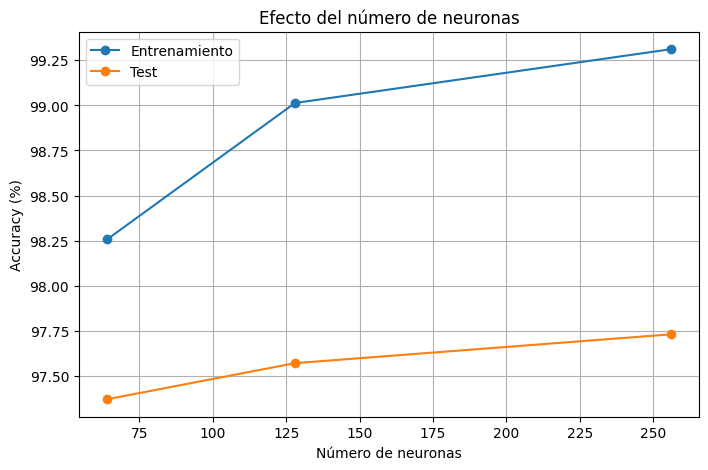

In [268]:
neuronas = [64, 128, 256]

accuracy_train_neuronas = [
    acc_train_64 * 100,
    acc_train * 100,
    acc_train_256 * 100
]

accuracy_test_neuronas = [
    acc_test_64 * 100,
    acc_test * 100,
    acc_test_256 * 100
]

plt.figure(figsize=(8, 5))

plt.plot(neuronas, accuracy_train_neuronas, marker='o', label='Entrenamiento')
plt.plot(neuronas, accuracy_test_neuronas, marker='o', label='Test')

plt.xlabel("Número de neuronas")
plt.ylabel("Accuracy (%)")
plt.title("Efecto del número de neuronas")
plt.legend()
plt.grid()

plt.show()

Al aumentar las neuronas de 64 a 128 y 256, el accuracy mejora tanto en entrenamiento como en test. Esto ocurre porque una red con más neuronas tiene mayor capacidad para aprender y reconocer los patrones de las imágenes. Sin embargo, la mejora es pequeña, especialmente en test. Por tanto, en estos experimentos utilizar más neuronas mejora ligeramente el resultado, pero también aumenta el tiempo de entrenamiento.


**Gráfica para comparación de épocas**

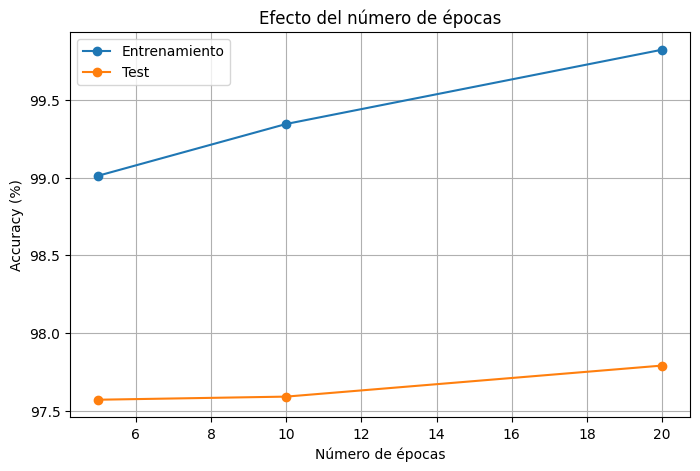

In [269]:
epocas = [5, 10, 20]

accuracy_train_epocas = [
    acc_train * 100,
    acc_train_10 * 100,
    acc_train_20 * 100
]

accuracy_test_epocas = [
    acc_test * 100,
    acc_test_10 * 100,
    acc_test_20 * 100
]

plt.figure(figsize=(8, 5))

plt.plot(epocas, accuracy_train_epocas, marker='o', label='Entrenamiento')
plt.plot(epocas, accuracy_test_epocas, marker='o', label='Test')

plt.xlabel("Número de épocas")
plt.ylabel("Accuracy (%)")
plt.title("Efecto del número de épocas")
plt.legend()
plt.grid()

plt.show()

Al aumentar el número de épocas, el accuracy de entrenamiento mejora porque el modelo tiene más oportunidades para aprender de los datos, pero en test apenas cambia. Esto se debe a que después de varias épocas el modelo ya ha aprendido gran parte de los patrones de los datos y seguir entrenando aporta menos mejoras sobre imágenes que no ha visto. Además, aumentar las épocas hace que el entrenamiento tarde más.


**Gráfica de comparación de optimizadores**

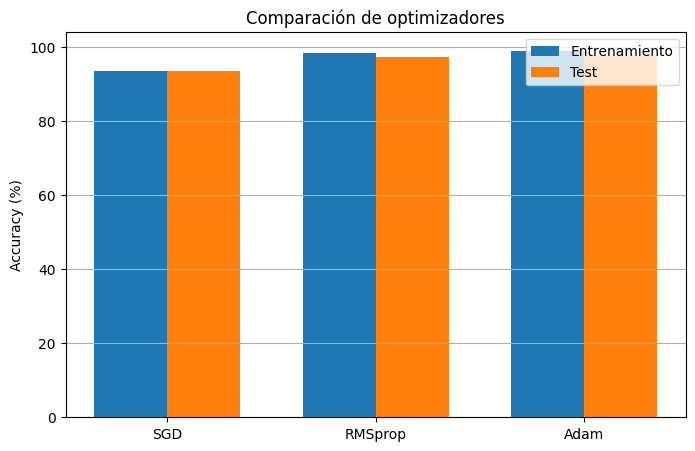

In [270]:
optimizadores = ["SGD", "RMSprop", "Adam"]

accuracy_train_optimizadores = [
    acc_train_sgd * 100,
    acc_train_rmsprop * 100,
    acc_train * 100
]

accuracy_test_optimizadores = [
    acc_test_sgd * 100,
    acc_test_rmsprop * 100,
    acc_test * 100
]

x = np.arange(len(optimizadores))
ancho = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - ancho/2, accuracy_train_optimizadores, ancho, label="Entrenamiento")
plt.bar(x + ancho/2, accuracy_test_optimizadores, ancho, label="Test")

plt.xticks(x, optimizadores)
plt.ylabel("Accuracy (%)")
plt.title("Comparación de optimizadores")
plt.legend()
plt.grid(axis='y')

plt.show()

Se puede observar que SGD obtiene un resultado bastante peor que RMSprop y Adam. Esto puede deberse a que SGD necesita más épocas para conseguir un buen aprendizaje, mientras que con solo 5 épocas no consigue aprender tan bien. RMSprop y Adam obtienen resultados más parecidos porque consiguen ajustar los pesos de una forma más rápida en esta configuración.


**Gráfica de comparación de batch size**

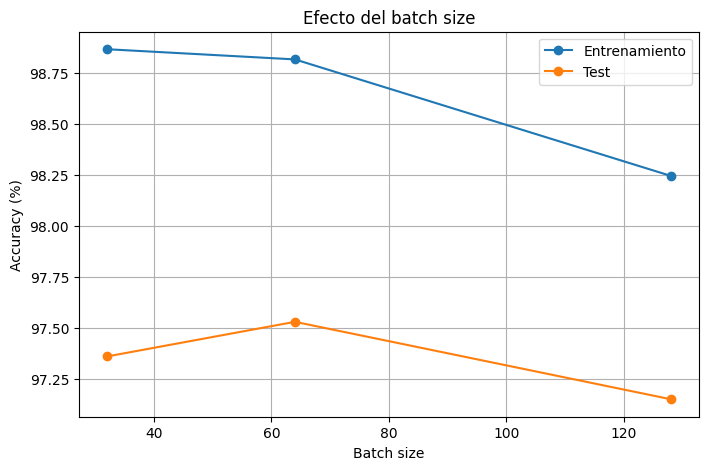

In [271]:
batch_sizes = [32, 64, 128]

accuracy_train_batch = [
    acc_train_batch32 * 100,
    acc_train_batch64 * 100,
    acc_train_batch128 * 100
]

accuracy_test_batch = [
    acc_test_batch32 * 100,
    acc_test_batch64 * 100,
    acc_test_batch128 * 100
]

plt.figure(figsize=(8, 5))

plt.plot(batch_sizes, accuracy_train_batch, marker='o', label='Entrenamiento')
plt.plot(batch_sizes, accuracy_test_batch, marker='o', label='Test')

plt.xlabel("Batch size")
plt.ylabel("Accuracy (%)")
plt.title("Efecto del batch size")
plt.legend()
plt.grid()

plt.show()

Los resultados son bastante parecidos para los tres tamaños de batch, aunque el accuracy disminuye un poco al utilizar 128. También se puede observar que los tamaños de batch más grandes necesitan menos tiempo de entrenamiento. Al utilizar un batch más grande, se actualizan los pesos menos veces durante cada época, por lo que con solo 5 épocas puede que el modelo no tenga tantas oportunidades de ajustar los pesos.


**Gráfica general de todas las configuraciones**

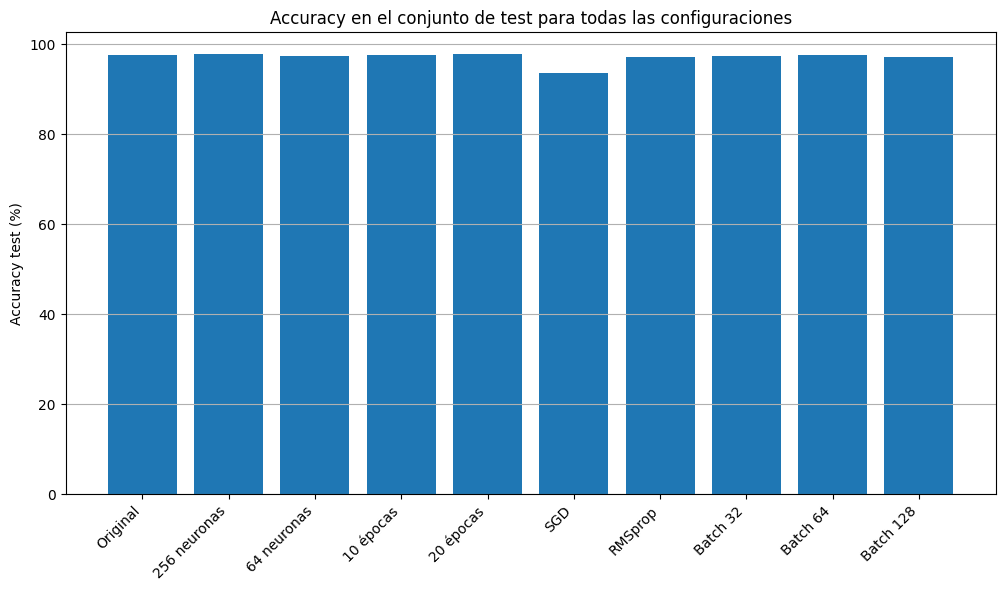

In [272]:
configuraciones = [
    "Original",
    "256 neuronas",
    "64 neuronas",
    "10 épocas",
    "20 épocas",
    "SGD",
    "RMSprop",
    "Batch 32",
    "Batch 64",
    "Batch 128"
]

accuracy_test = [
    acc_test * 100,
    acc_test_256 * 100,
    acc_test_64 * 100,
    acc_test_10 * 100,
    acc_test_20 * 100,
    acc_test_sgd * 100,
    acc_test_rmsprop * 100,
    acc_test_batch32 * 100,
    acc_test_batch64 * 100,
    acc_test_batch128 * 100
]

plt.figure(figsize=(12, 6))

plt.bar(configuraciones, accuracy_test)

plt.ylabel("Accuracy test (%)")
plt.title("Accuracy en el conjunto de test para todas las configuraciones")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')

plt.show()

En general, todas las configuraciones excepto SGD consiguen un accuracy de test cercano al 97%. La configuración de 20 épocas obtiene el resultado más alto, aunque la diferencia con otras configuraciones es pequeña.


**Gráficas del tiempo de entrenamiento**

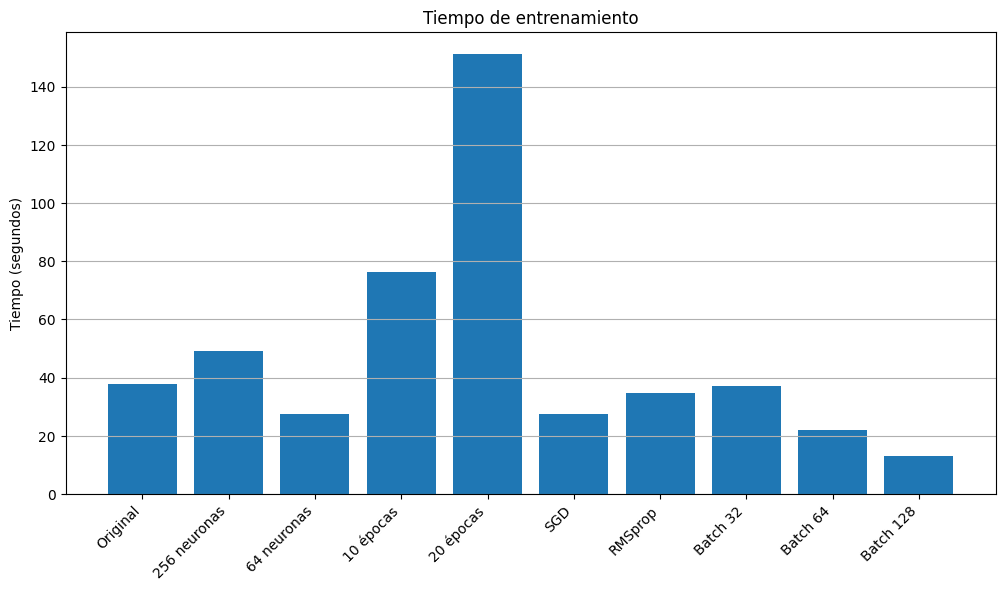

In [273]:
tiempos = [
    tiempo_original,
    tiempo_256,
    tiempo_64,
    tiempo_10,
    tiempo_20,
    tiempo_sgd,
    tiempo_rmsprop,
    tiempo_batch32,
    tiempo_batch64,
    tiempo_batch128
]

plt.figure(figsize=(12, 6))

plt.bar(configuraciones, tiempos)

plt.ylabel("Tiempo (segundos)")
plt.title("Tiempo de entrenamiento")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')

plt.show()

El tiempo aumenta bastante al utilizar más épocas porque el modelo tiene que recorrer los datos más veces. En cambio, al aumentar el batch size el entrenamiento es más rápido porque en cada actualización se utilizan más imágenes y, por tanto, se necesitan menos actualizaciones para completar una época. El número de neuronas también influye, ya que más neuronas implican más cálculos.


## **Conclusión**

Después de comparar todas las configuraciones, la que obtiene el mejor resultado en test es la de 20 épocas, 128 neuronas y Adam.

Aumentar las neuronas mejora un poco el resultado, aunque la diferencia es pequeña. Aumentar las épocas mejora más el entrenamiento y, en este caso, también consigue el mejor resultado en test. En cuanto a los optimizadores, SGD obtiene peores resultados, mientras que Adam y RMSprop son más parecidos. Los diferentes batch size dan resultados similares, aunque 128 es algo peor.

Por tanto, la configuración de 20 épocas, 128 neuronas y Adam será la que guardemos como el mejor modelo.

In [274]:
# Lo guardamos
model4.save("mejor_modelo_mnist.keras")

In [275]:
# Cargamos el modelo guardado
modelo_guardado = tf.keras.models.load_model("mejor_modelo_mnist.keras")

# Comprobar su rendimiento en test
modelo_guardado.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9779 - loss: 0.1139


[0.11389251798391342, 0.9779000282287598]